# Tahap 2 KDD - Preprocessing

Menyeragamkan citra agar fitur tekstur dapat dibandingkan secara adil.

| | |
|---|---|
| **Tujuan** | Crop tengah persegi, resize 256x256, grayscale, CLAHE, denoise. |
| **Masukan** | `data/processed/splits.csv` + foto asli |
| **Keluaran** | `data/interim/gray/...` dan `data/interim/rgb/...` |

Rantai proses tiap foto:

1. **Crop tengah persegi** lalu **resize 256x256** (`INTER_AREA`) - semua foto berukuran sama.
2. **Grayscale** - LBP bekerja pada intensitas keabuan (sesuai jurnal).
3. **CLAHE** (clipLimit 2.0, tile 8x8) - meratakan kontras lokal; padanan "normalisasi" pada jurnal.
4. **Gaussian blur 3x3** - meredam noise sensor.
5. Salinan RGB hasil resize disimpan terpisah untuk jalur CNN.

Fungsi `preprocess_gray` / `preprocess_rgb` didefinisikan sebagai fungsi bernama agar dipakai ulang oleh tahap prediksi nanti.

In [1]:
%matplotlib inline

import os
import sys
from pathlib import Path

# Pastikan kernel berada di folder induk proyek agar `import config` berfungsi
HERE = Path.cwd().resolve()
ROOT = HERE.parent if HERE.name == "notebooks" else HERE
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import config as C

print("ROOT      :", ROOT)
print("Folder data:", C.RAW_DIR)
print("Kelas     :", C.CLASSES)

import random

import cv2
import matplotlib.pyplot as plt
import pandas as pd

ROOT      : D:\Perkuliahan\Machine Learning teori\Ban_Motor
Folder data: D:\Perkuliahan\Machine Learning teori\Ban_Motor\data\raw
Kelas     : ['baik', 'sedang', 'aus']


In [2]:
def center_square(img):
    h, w = img.shape[:2]
    s = min(h, w)
    y0, x0 = (h - s) // 2, (w - s) // 2
    return img[y0:y0 + s, x0:x0 + s]


def preprocess_rgb(img_bgr):
    """Crop tengah (persegi) lalu resize. Dipakai juga untuk jalur CNN."""
    return cv2.resize(center_square(img_bgr), (C.IMG_SIZE, C.IMG_SIZE),
                      interpolation=cv2.INTER_AREA)


def preprocess_gray(img_bgr):
    """Pipeline untuk machine learning klasik."""
    sq = preprocess_rgb(img_bgr)
    gray = cv2.cvtColor(sq, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))   # normalisasi kontras/cahaya
    gray = clahe.apply(gray)
    return cv2.GaussianBlur(gray, (3, 3), 0)                      # redam noise

In [3]:
df = pd.read_csv(C.PROCESSED_DIR / "splits.csv")

gagal = 0
for _, r in df.iterrows():
    img = cv2.imread(r["path"])
    if img is None:
        gagal += 1
        print("gagal baca:", r["path"])
        continue
    name = Path(r["path"]).stem + ".png"
    for kind, out in (("gray", preprocess_gray(img)), ("rgb", preprocess_rgb(img))):
        d = C.INTERIM_DIR / kind / r["split"] / r["label"]
        d.mkdir(parents=True, exist_ok=True)
        cv2.imwrite(str(d / name), out)

print("Preprocessing selesai ->", C.INTERIM_DIR)
print("foto gagal dibaca:", gagal)
for kind in ("gray", "rgb"):
    n = len(list((C.INTERIM_DIR / kind).rglob("*.png")))
    print(f"  {kind}: {n} file  (splits.csv: {len(df)} baris)")

Preprocessing selesai -> D:\Perkuliahan\Machine Learning teori\Ban_Motor\data\interim
foto gagal dibaca: 0
  gray: 529 file  (splits.csv: 529 baris)
  rgb: 529 file  (splits.csv: 529 baris)


### Pemeriksaan visual

Buka 4 foto acak per kelas (data train). **Alur tapak harus masih terlihat jelas.** Bila CLAHE membuat noise berlebihan, kecilkan `clipLimit` di fungsi `preprocess_gray` lalu jalankan ulang notebook ini.

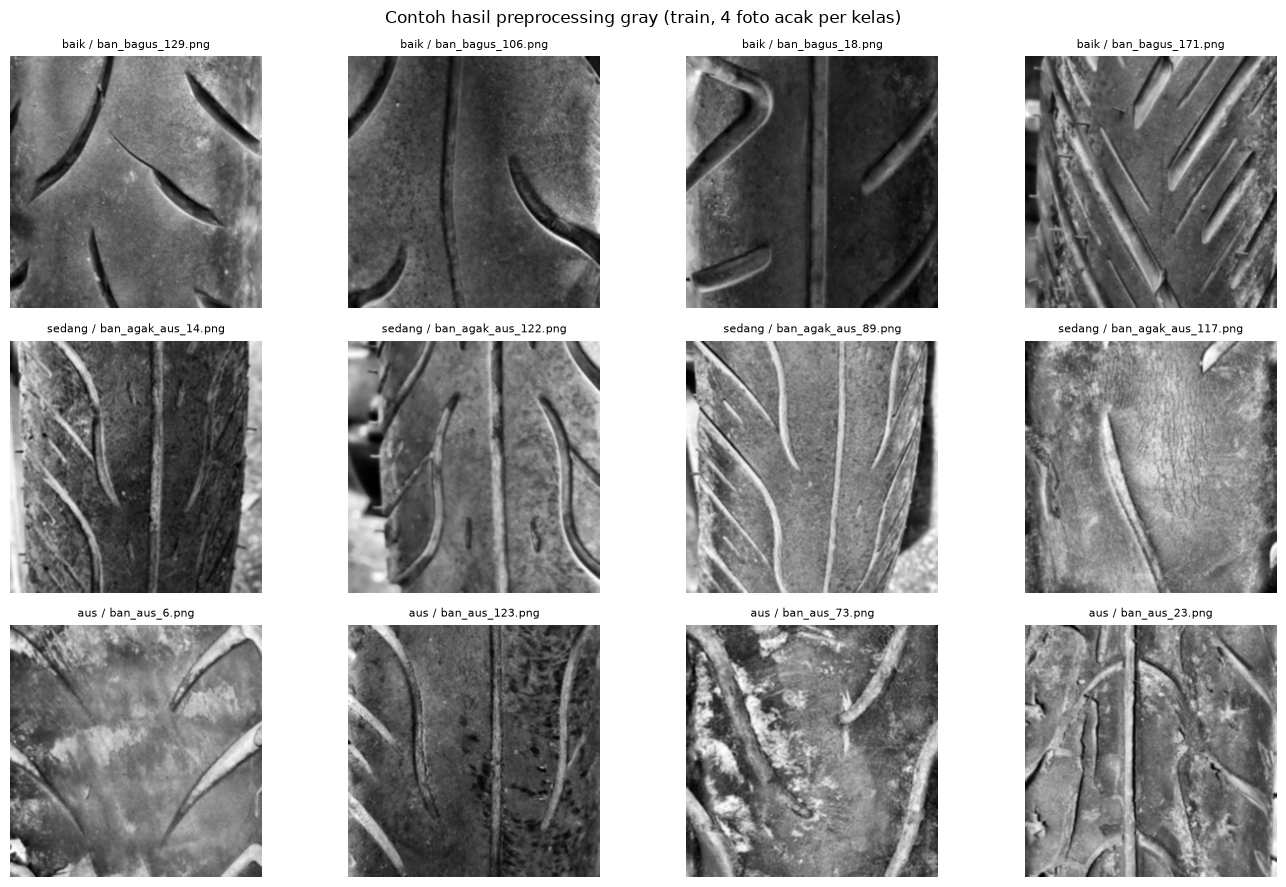

In [4]:
random.seed(C.RANDOM_STATE)
fig, axes = plt.subplots(len(C.CLASSES), 4, figsize=(14, 3 * len(C.CLASSES)))
for i, label in enumerate(C.CLASSES):
    pool = sorted((C.INTERIM_DIR / "gray" / "train" / label).glob("*.png"))
    for j, p in enumerate(random.sample(pool, 4)):
        g = cv2.imread(str(p), 0)
        axes[i, j].imshow(g, cmap="gray")
        axes[i, j].set_title(f"{label} / {p.name}", fontsize=8)
        axes[i, j].axis("off")
plt.suptitle("Contoh hasil preprocessing gray (train, 4 foto acak per kelas)")
plt.tight_layout()
plt.show()

## Periksa sebelum lanjut (Tahap 3)

- [ ] Alur tapak masih terlihat jelas pada gambar di atas.
- [ ] Jumlah file gray/rgb sama dengan jumlah baris `splits.csv`.
- [ ] Data mentah di `data/raw` tidak berubah.
- [ ] Augmentasi (jika dipakai nanti) hanya pada data train dan setelah split.